# Adult Income: Classical ML and PyTorch

A post-coursework extension with validation-only selection, a separate official UCI test, and three DL seeds. Original coursework is preserved. This notebook uses the modular source in `src/adult_benchmark.py`.

Install dependencies with `%pip install -r requirements-improved.txt` if needed. CPU is sufficient.

In [1]:
from pathlib import Path
import sys
import json
import subprocess
import pandas as pd
from IPython.display import display, Image

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/adult_benchmark.py').exists()), None)
if ROOT is None:
    ROOT = Path('/content/adult-income-improvement')
    subprocess.run(['git', 'clone', 'https://github.com/VietAnh1803/HCMUT_ML_AdultCensusIncome_Pipeline.git', str(ROOT)], check=True)
sys.path.insert(0, str(ROOT / 'src'))
OUT = ROOT / 'reports/improved'
print('Source:', ROOT)

Source: C:\Hoc_Tap\cv\adult-income-improvement


## Run or inspect a recorded experiment
The shipped results are from the actual CPU experiment. Reuse is explicit; turn it off to download the official data and train again. Training and threshold selection finish before final test labels are parsed.

In [2]:
REUSE_RECORDED_RUN = True
if not REUSE_RECORDED_RUN or not (OUT / 'metrics.json').exists():
    from adult_benchmark import main
    main(OUT, ROOT / '.cache/adult')
else:
    print('Reusing the recorded, verified CPU run; this cell does not retrain.')
report = json.loads((OUT / 'metrics.json').read_text())
display(pd.Series(report['split']).to_frame('Split evidence'))

Reusing the recorded, verified CPU run; this cell does not retrain.


,Split evidence
seed,42
train_rows,26028
validation_rows,6508
original_train_rows,32561
train_feature_duplicates_removed,25
split_ids_sha256,8b65a245597770268e00fc818f7705fd6b958b02679fd5...
source,https://archive.ics.uci.edu/static/public/2/ad...
source_sha256,{'adult.data': '5b00264637dbfec36bdeaab5676b0b...
test_rows,16249
original_test_rows,16281


## Validation comparison
Select on AP. The two legacy recipes are predefined controls. No test score is used here.

In [3]:
validation = pd.json_normalize(report['validation_experiments'])
display(validation[['name', 'family', 'validation.average_precision', 'validation.roc_auc', 'fit_seconds']].sort_values('validation.average_precision', ascending=False))
display(pd.Series(report['selection']).to_frame('Frozen choices'))

,name,family,validation.average_precision,validation.roc_auc,fit_seconds
5,lightgbm_small_leaves,classic,0.843210,0.932306,1.187184
4,lightgbm_regularized,classic,0.843191,0.932739,1.479969
3,legacy_lightgbm,classic,0.841132,0.931935,1.076334
2,random_forest,classic,0.808458,0.918587,2.039133
8,mlp_128_64,deep_learning,0.800632,0.918765,9.429727
7,mlp_64_32,deep_learning,0.799756,0.918827,13.290335
6,legacy_mlp,deep_learning,0.795787,0.916605,14.406926
1,linear_svm,classic,0.782718,0.910748,0.616629
0,logistic,classic,0.782419,0.910775,0.548104


,Frozen choices
criterion,validation average precision
best_classic,lightgbm_small_leaves
best_mlp,mlp_128_64
test_models,"[legacy_lightgbm, legacy_mlp, lightgbm_small_l..."
thresholds,"{'logistic': 0.3022786633024744, 'linear_svm':..."
extra_mlp_seeds,"[43, 44]"
split_ids_sha256,8b65a245597770268e00fc818f7705fd6b958b02679fd5...


## Final test and DL stability
Only selected models and controls are graded. These are distinct from historical coursework scores.

In [4]:
display(pd.DataFrame(report['test']).T[['accuracy', 'average_precision', 'roc_auc', 'f1_positive', 'f1_macro', 'log_loss']])
display(pd.DataFrame(report['selected_mlp_seed_repeats'])[['seed', 'accuracy', 'average_precision', 'roc_auc']])
assert all(report['checks'].values())
print('ADULT_REPORT_VERIFIED: all recorded protocol checks passed')

,accuracy,average_precision,roc_auc,f1_positive,f1_macro,log_loss
legacy_lightgbm,0.842944,0.821314,0.925387,0.715369,0.803461,0.316513
legacy_mlp,0.813035,0.771856,0.908852,0.682151,0.774859,0.373338
lightgbm_small_leaves,0.867253,0.826091,0.927633,0.722215,0.817502,0.276307
mlp_128_64,0.840852,0.776163,0.910312,0.693602,0.793056,0.310932


,seed,accuracy,average_precision,roc_auc
0,42,0.840852,0.776163,0.910312
1,43,0.844975,0.777277,0.910907
2,44,0.842698,0.776287,0.910316


ADULT_REPORT_VERIFIED: all recorded protocol checks passed


## Measured comparison
Accuracy gains include validation threshold changes. AP gains are modest, and the MLP does not outperform LightGBM. See the improvement report and paired bootstrap for uncertainty. This 1994 census dataset is a historical learning benchmark.

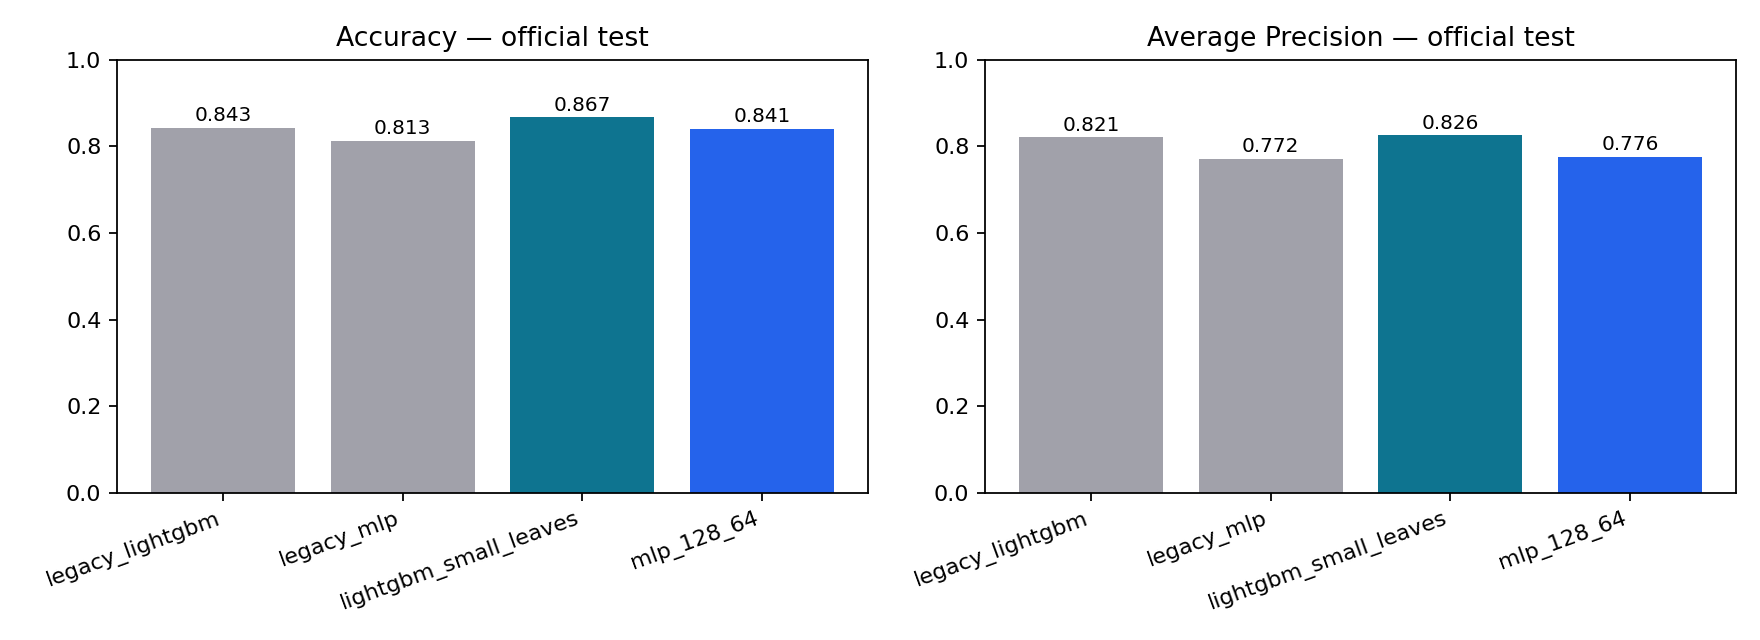

,Recorded environment
python,"3.12.0 (tags/v3.12.0:0fb18b0, Oct 2 2023, 13:..."
torch_device,cpu
threads,4
packages,"{'torch': '2.9.1', 'scikit-learn': '1.7.2', 'l..."


In [5]:
display(Image(filename=str(OUT / 'comparison.png')))
display(pd.Series(report['environment']).to_frame('Recorded environment'))